# Lecture 6 — Class Exercise
## Choropleth Maps

> **Push to:** `week06/lecture08_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


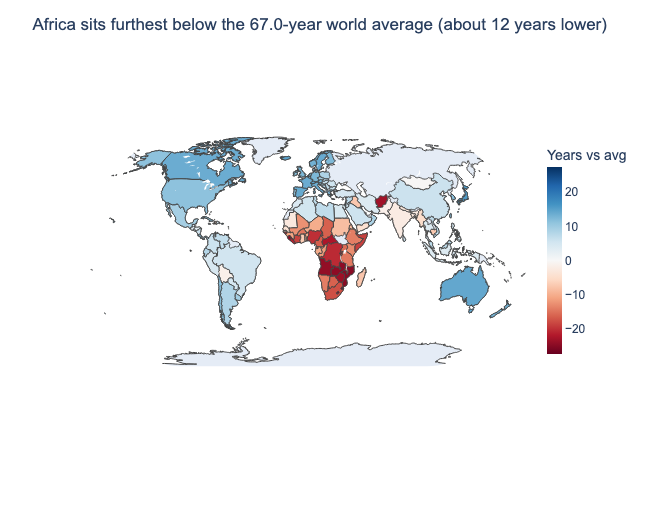

In [4]:
# Task 1 - world choropleth: life expectancy vs the world average (diverging scale)
# YOUR CODE HERE
gm_2007 = px.data.gapminder().query('year == 2007').copy()  

world_avg = gm_2007['lifeExp'].mean()                
gm_2007['deviation'] = gm_2007['lifeExp'] - world_avg 

# Which continent is furthest below average? (used in the title)
cont_dev = gm_2007.groupby('continent')['deviation'].mean()
worst = cont_dev.idxmin()                              
worst_gap = abs(cont_dev.min())                       

fig = px.choropleth(
    gm_2007,
    locations='iso_alpha',                  
    locationmode='ISO-3',                  
    color='deviation',                      
    color_continuous_scale='RdBu',          
    color_continuous_midpoint=0,            
    hover_name='country',
    hover_data={'lifeExp': ':.1f', 'deviation': ':+.1f', 'iso_alpha': False},  
    labels={'deviation': 'Years vs average', 'lifeExp': 'Life expectancy'},
    projection='natural earth',
    height=520,
)
fig.update_layout(
    title=f'{worst} sits furthest below the {world_avg:.1f}-year world average (about {worst_gap:.0f} years lower)',
    font=dict(family='Arial', size=12),
    geo=dict(showframe=False),              
    coloraxis_colorbar=dict(title='Years vs avg', thickness=15, len=0.6),
)
fig.show()

## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** *(URL or description)*

**Chart type chosen** (`px.choropleth` or `px.choropleth_mapbox`) **and reason:**

*Your answer here*

**Colour scale chosen** (sequential or diverging) **and reason:**

*Your answer here*


{'NAME_1': 'Andaman and Nicobar'}
Unmatched: []


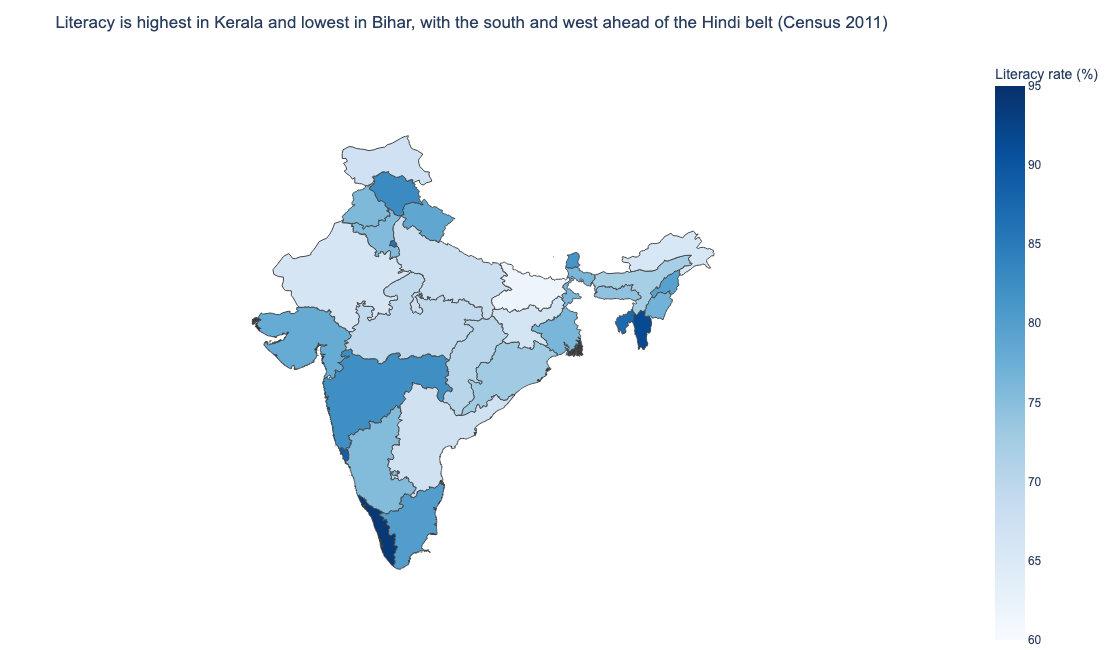

In [4]:
# Task 2 - my own GeoJSON: literacy rate by Indian state
# YOUR CODE HERE

import os, json, requests                            
import pandas as pd                               
import plotly.express as px                       

url = "https://raw.githubusercontent.com/Subhash9325/GeoJson-Data-of-Indian-States/master/Indian_States"

# Step 1: download + shrink only if the small file is missing or empty
if not os.path.exists('india_states_small.geojson') or os.path.getsize('india_states_small.geojson') == 0:
    r = requests.get(url, timeout=60)                
    r.raise_for_status()                            
    big = r.json()                                  

    def thin(ring, step=15):                         
        pts = ring if len(ring) <= 60 else ring[::step]   
        if pts[0] != pts[-1]:                        
            pts = pts + [pts[0]]
        if len(pts) < 4:                            
            pts = ring
        return [[round(x, 2), round(y, 2)] for x, y in pts]

    def simplify(geom):                              
        if geom['type'] == 'Polygon':
            return {'type': 'Polygon', 'coordinates': [thin(r) for r in geom['coordinates']]}
        return {'type': 'MultiPolygon',
                'coordinates': [[thin(r) for r in poly] for poly in geom['coordinates']]}

    small = {'type': 'FeatureCollection',
             'features': [{'type': 'Feature',
                           'properties': {'NAME_1': f['properties']['NAME_1']},   
                           'geometry': simplify(f['geometry'])}
                          for f in big['features']]}

    with open('india_states_small.geojson', 'w') as f:        
        json.dump(small, f, separators=(',', ':'))

# Step 2: load the small GeoJSON
with open('india_states_small.geojson', 'r') as file:
    my_geojson = json.load(file)

print(my_geojson['features'][0]['properties'])       

# Step 3: data - literacy rate % (Census 2011, approximate: verify before submitting)

lit = pd.DataFrame({
    'state': ['Kerala','Mizoram','Goa','Tripura','Delhi','Chandigarh','Puducherry','Himachal Pradesh',
              'Maharashtra','Sikkim','Tamil Nadu','Nagaland','Uttaranchal','Gujarat','Punjab','West Bengal',
              'Haryana','Karnataka','Manipur','Meghalaya','Orissa','Assam','Chhattisgarh','Madhya Pradesh',
              'Uttar Pradesh','Jammu and Kashmir','Andhra Pradesh','Jharkhand','Rajasthan','Arunachal Pradesh','Bihar'],
    'literacy': [94.0,91.6,88.7,87.2,86.2,86.1,85.9,82.8,
                 82.3,81.4,80.1,79.6,78.8,78.0,75.8,76.3,
                 75.6,75.4,76.9,74.4,72.9,72.2,70.3,69.3,
                 67.7,67.2,67.0,66.4,66.1,65.4,61.8],
})


geo_names = {ft['properties']['NAME_1'] for ft in my_geojson['features']}
print('Unmatched:', sorted(set(lit['state']) - geo_names))

# Step 4: the map
fig = px.choropleth(
    data_frame=lit,
    geojson=my_geojson,                              
    locations='state',                               
    featureidkey='properties.NAME_1',                
    color='literacy',                                
    color_continuous_scale='Blues',                  
    range_color=[60, 95],                            
    hover_name='state',
    hover_data={'state': False, 'literacy': ':.1f'},
    labels={'literacy': 'Literacy rate (%)'},
    fitbounds='locations',                          
    height=650,
)
fig.update_geos(visible=False)                       

top = lit.loc[lit['literacy'].idxmax(), 'state']     
low = lit.loc[lit['literacy'].idxmin(), 'state']    
fig.update_layout(
    title=f'Literacy is highest in {top} and lowest in {low}, with the south and west ahead of the Hindi belt (Census 2011)',
    font=dict(family='Arial', size=12),
    margin=dict(l=0, r=0, t=55, b=0),
)
fig.show()  